In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## load the dataset
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


**Problem Statement**: Predict the Total Bill

In [3]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


[Text(0, 2, '157'), Text(0, 2, '87')]

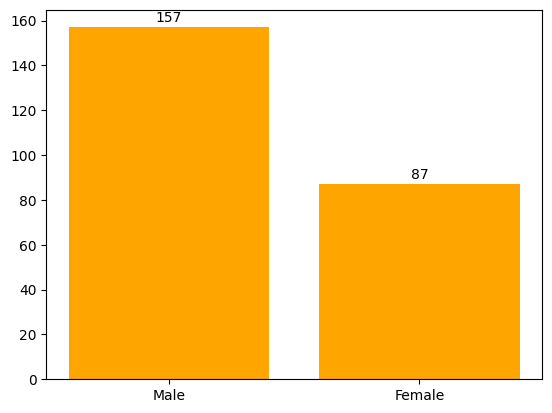

In [4]:
gender = tips['sex'].value_counts()
bars = plt.bar(x = gender.index, height = gender.values, color = 'Orange')
plt.bar_label(bars, labels = gender.values, padding = 2)

[Text(0, 2, '151'), Text(0, 2, '93')]

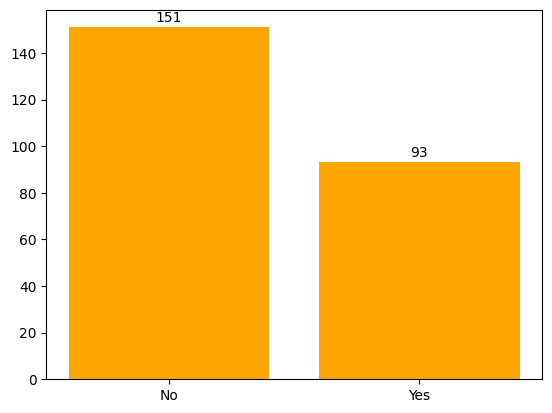

In [5]:
smoker = tips['smoker'].value_counts()
bars = plt.bar(x = smoker.index, height = smoker.values, color = 'Orange')
plt.bar_label(bars, labels = smoker.values, padding = 2)

[Text(0, 2, '87'), Text(0, 2, '76'), Text(0, 2, '62'), Text(0, 2, '19')]

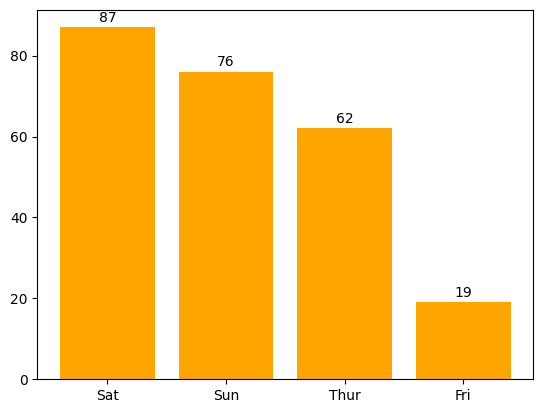

In [6]:
day = tips['day'].value_counts()
bars = plt.bar(x = day.index, height = day.values, color = 'Orange')
plt.bar_label(bars, labels = day.values, padding = 2)

[Text(0, 2, '176'), Text(0, 2, '68')]

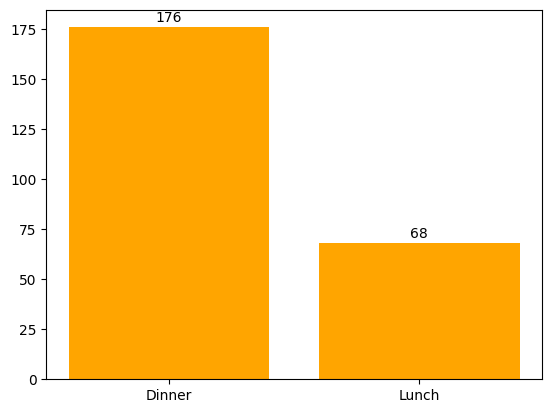

In [7]:
time = tips['time'].value_counts()
bars = plt.bar(x = time.index, height = time.values, color = 'Orange')
plt.bar_label(bars, labels = time.values, padding = 2)

### Feature Encoding

Label Encoding and One Hot Encoding

In [8]:
## Independent and Dependent Features

x = tips.drop('total_bill', axis = 1)
y = tips['total_bill']

In [9]:
## train, test, split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 10)

### Question: Why we are doing **Feature Encoding** after train-test-split?

**Answer**:
There will always be a problem of data leakage if we don't divide this into train and test. 

Data Leakage basically means the model should have no information about the test data.

Whatever technique we are using to train the data, same technique should be applied for the test data.

In [10]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [11]:
from sklearn.preprocessing import LabelEncoder

smoker = LabelEncoder()
time = LabelEncoder()
sex = LabelEncoder()

In [12]:
X_train['smoker'] = smoker.fit_transform(X_train['smoker'])
X_train['time'] = time.fit_transform(X_train['time'])
X_train['sex'] = sex.fit_transform(X_train['sex'])

In [13]:
X_train.head()

,tip,sex,smoker,day,time,size
58,1.76,1,1,Sat,0,2
1,1.66,1,0,Sun,0,3
2,3.50,1,0,Sun,0,3
68,2.01,1,0,Sat,0,2
184,3.00,1,1,Sun,0,2


In [14]:
X_test['smoker'] = smoker.transform(X_test['smoker'])
X_test['time'] = time.transform(X_test['time'])
X_test['sex'] = sex.transform(X_test['sex'])

In [15]:
## One Hot Encoding --- ColumnTransformer

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ct = ColumnTransformer(
    transformers = [
        ('onehot', OneHotEncoder(
            drop = 'first' ## remove the first feature  
            ), 
         3 ## index of the column to apply
        )
    ], 
    remainder = 'passthrough' ## keep the other columns as it is.
)

In [16]:
ct.fit_transform(X_train)

ValueError: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

In [17]:
ct = ColumnTransformer(
    transformers = [
        ('onehot', OneHotEncoder(
            drop = 'first'   
            ), 
         [3] ## index should be in the form of list, otherwise it will give an error.
        )
    ], 
    remainder = 'passthrough' 
)

In [18]:
ct.fit_transform(X_train)

array([[1., 0., 0., ..., 1., 0., 2.],
       [0., 1., 0., ..., 0., 0., 3.],
       [0., 1., 0., ..., 0., 0., 3.],
       ...,
       [1., 0., 0., ..., 0., 0., 2.],
       [0., 0., 1., ..., 0., 1., 6.],
       [0., 1., 0., ..., 0., 0., 2.]], shape=(183, 8))

In [19]:
import sys
import numpy
numpy.set_printoptions(threshold=sys.maxsize) 
## the above code is  capable to print the whole array without truncation.
ct.fit_transform(X_train)

array([[ 1.  ,  0.  ,  0.  ,  1.76,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  1.66,  1.  ,  0.  ,  0.  ,  3.  ],
       [ 0.  ,  1.  ,  0.  ,  3.5 ,  1.  ,  0.  ,  0.  ,  3.  ],
       [ 1.  ,  0.  ,  0.  ,  2.01,  1.  ,  0.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  3.  ,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  4.  ,  0.  ,  1.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  5.2 ,  0.  ,  0.  ,  0.  ,  4.  ],
       [ 0.  ,  0.  ,  1.  ,  4.  ,  1.  ,  1.  ,  1.  ,  4.  ],
       [ 0.  ,  0.  ,  1.  ,  5.  ,  1.  ,  0.  ,  1.  ,  5.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  1.75,  1.  ,  0.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  3.12,  1.  ,  0.  ,  0.  ,  4.  ],
       [ 0.  ,  0.  ,  1.  ,  3.  ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  5.  ,  1.  ,  0.  ,  0.  ,  3.  ],
       [ 0.  ,  0.  ,  1.  ,  4.  ,  1.  ,  0.  ,  1.  ,  2.  ],
       [ 1.  ,  0.  ,  0.

In [20]:
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

## Apply the Algorithm

In [21]:
from sklearn.svm import SVR
svr = SVR()
svr.fit(X_train, y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = svr.predict(X_test)
print('Mean Squared Error:', mean_squared_error(y_test, y_pred))
print('Mean Absolute Error:', mean_absolute_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2 Score:', r2_score(y_test, y_pred))

Mean Squared Error: 45.692136151683385
Mean Absolute Error: 4.1486423210190235
Root Mean Squared Error: 6.759595857126621
R2 Score: 0.46028114561159283


In [23]:
## Hyperparameter Tuning using GridSearchCV
from sklearn.model_selection import GridSearchCV

params_grid = {
    'C' : [0.1, 1, 10, 100, 1000],
    'gamma' : [1, 0.1, 0.01, 0.001, 0.0001],
    'kernel' : ['rbf'],
}

In [24]:
grid = GridSearchCV(estimator = svr, param_grid = params_grid, refit = True, verbose = 3)
grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.067 total time=   0.0s
[CV 2/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.058 total time=   0.0s
[CV 3/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.145 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.025 total time=   0.0s
[CV 5/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.089 total time=   0.0s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.013 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.021 total time=   0.0s
[CV 3/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.010 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.124 total time=   0.0s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.050 total time=   0.0s
[CV 1/5] END ....C=0.1, gamma=0.01, kernel=rbf;, score=-0.053 total time=   0.0s
[CV 2/5] END ....C=0.1, gamma=0.01, kernel=rbf;

,estimator,SVR()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'rbf'


In [25]:
grid.best_params_

{'C': 1000, 'gamma': 0.0001, 'kernel': 'rbf'}

In [26]:
y_pred = grid.predict(X_test)
print('Mean Squared Error:', mean_squared_error(y_test, y_pred))
print('Mean Absolute Error:', mean_absolute_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2 Score:', r2_score(y_test, y_pred))

Mean Squared Error: 41.63859886764171
Mean Absolute Error: 3.8685147526100234
Root Mean Squared Error: 6.452797755054912
R2 Score: 0.5081618245078687
